# Modelo base de temperatura global: CO₂ + ENSO

Este notebook descarga tres series públicas, las une por año y ajusta un modelo lineal base:

| Serie | Fuente | Qué aporta |
|---|---|---|
| Anomalía de temperatura global (°C, vs. 1951–1980) | NASA GISTEMP v4 | Variable objetivo |
| CO₂ anual en Mauna Loa (ppm) | NOAA GML | Tendencia de fondo (forzamiento) |
| Índice ONI (°C) | NOAA CPC | El Niño / La Niña: variación año a año |

**Modelo:** `anomalía ~ ln(CO₂/280) + ONI del año + ONI del año anterior`

El CO₂ entra en logaritmo porque su forzamiento radiativo crece de forma logarítmica (ΔF ≈ 5.35·ln(C/C₀) W/m²).
La validación es temporal: se entrena hasta 2010 y se evalúa de 2011 en adelante.

## 1. Configuración

In [2]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

URLS = {
    "gistemp.csv": "https://data.giss.nasa.gov/gistemp/tabledata_v4/GLB.Ts+dSST.csv",
    "co2_annmean_mlo.csv": "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_annmean_mlo.csv",
    "oni.ascii.txt": "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt",
}

TRAIN_END = 2010        # último año del conjunto de entrenamiento
CO2_PREINDUSTRIAL = 280 # ppm, referencia para ln(CO2/280)

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False})

Fontconfig warning: ignoring UTF-8: not a valid region tag
Matplotlib is building the font cache; this may take a moment.


## 2. Descarga (con caché local)

Cada archivo se guarda en `data/`. Si ya existe, se reutiliza; borra el archivo para forzar una descarga nueva.
Si algún servidor no responde, descarga el archivo a mano desde la URL y ponlo en `data/` con el mismo nombre.

In [3]:
def fetch(name: str, force: bool = False) -> str:
    path = DATA_DIR / name
    if path.exists() and not force:
        print(f"[caché] {name}")
        return path.read_text()
    url = URLS[name]
    r = requests.get(url, timeout=60, headers={"User-Agent": "climate-notebook/1.0"})
    r.raise_for_status()
    path.write_text(r.text)
    print(f"[descargado] {name} ({len(r.text):,} bytes)")
    return r.text

raw = {name: fetch(name) for name in URLS}

[descargado] gistemp.csv (12,886 bytes)
[descargado] co2_annmean_mlo.csv (3,134 bytes)
[descargado] oni.ascii.txt (23,025 bytes)


## 3. Lectura y limpieza

**GISTEMP.** La primera línea es un título; la segunda trae los encabezados. Los meses aún no publicados aparecen como `***`.
Usamos la columna `J-D` (promedio enero–diciembre) y descartamos el año en curso si está incompleto.

In [4]:
gis = pd.read_csv(io.StringIO(raw["gistemp.csv"]), skiprows=1, na_values="***")
gis = gis.rename(columns={"Year": "year", "J-D": "temp_anom"})[["year", "temp_anom"]]
gis = gis.dropna().astype({"year": int})
print(gis.tail(3))
print(f"GISTEMP: {gis.year.min()}–{gis.year.max()}, {len(gis)} años")

     year  temp_anom
143  2023       1.17
144  2024       1.28
145  2025       1.18
GISTEMP: 1880–2025, 146 años


**CO₂ Mauna Loa.** CSV con líneas de comentario que empiezan con `#`; columnas `year, mean, unc`.

In [5]:
co2 = pd.read_csv(io.StringIO(raw["co2_annmean_mlo.csv"]), comment="#")
co2.columns = [c.strip() for c in co2.columns]
co2 = co2.rename(columns={"mean": "co2_ppm"})[["year", "co2_ppm"]].astype({"year": int})
print(co2.tail(3))
print(f"CO₂: {co2.year.min()}–{co2.year.max()}, {len(co2)} años")

    year  co2_ppm
64  2023   421.08
65  2024   424.61
66  2025   427.35
CO₂: 1959–2025, 67 años


**ONI.** Texto separado por espacios con columnas `SEAS YR TOTAL ANOM`. Cada fila es una media móvil de 3 meses (DJF, JFM, …, NDJ).
Promediamos `ANOM` por año y exigimos las 12 temporadas para no usar años incompletos.

In [6]:
oni_raw = pd.read_csv(io.StringIO(raw["oni.ascii.txt"]), sep=r"\s+")
oni = (oni_raw.groupby("YR")["ANOM"]
       .agg(["mean", "count"])
       .query("count == 12")
       .rename(columns={"mean": "oni"})
       .reset_index()
       .rename(columns={"YR": "year"})[["year", "oni"]])
oni["oni_lag1"] = oni["oni"].shift(1)
print(oni.tail(3))
print(f"ONI: {oni.year.min()}–{oni.year.max()}, {len(oni)} años")

    year       oni  oni_lag1
73  2023  0.814167 -0.782500
74  2024  0.410000  0.814167
75  2025 -0.281667  0.410000
ONI: 1950–2025, 76 años


## 4. Unión por año

In [7]:
df = (gis.merge(co2, on="year", how="inner")
          .merge(oni, on="year", how="inner")
          .dropna()
          .sort_values("year")
          .reset_index(drop=True))
df["ln_co2"] = np.log(df["co2_ppm"] / CO2_PREINDUSTRIAL)
df.to_csv(DATA_DIR / "dataset_anual.csv", index=False)
print(f"Dataset unido: {df.year.min()}–{df.year.max()}, {len(df)} años")
df.tail()

Dataset unido: 1959–2025, 67 años


,year,temp_anom,co2_ppm,oni,oni_lag1,ln_co2
62,2021,0.85,416.41,-0.650833,-0.210833,0.396881
63,2022,0.89,418.53,-0.782500,-0.650833,0.401959
64,2023,1.17,421.08,0.814167,-0.782500,0.408033
65,2024,1.28,424.61,0.410000,0.814167,0.416381
66,2025,1.18,427.35,-0.281667,0.410000,0.422814


## 5. Exploración rápida

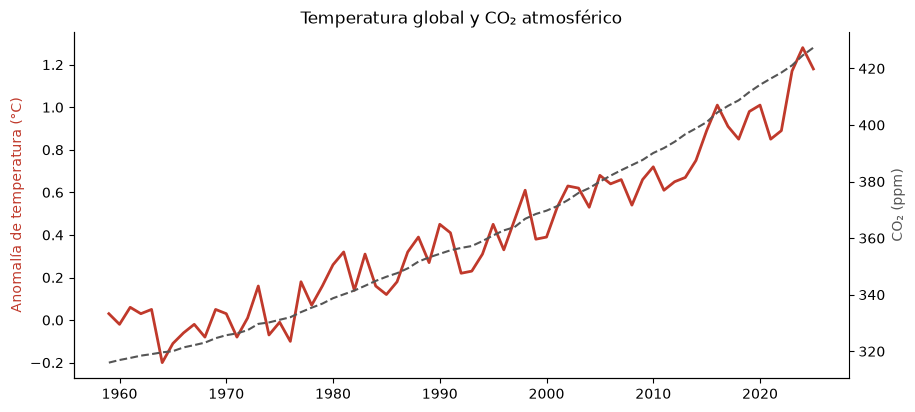

           temp_anom  ln_co2   oni  oni_lag1
temp_anom       1.00    0.96  0.09      0.11
ln_co2          0.96    1.00 -0.01     -0.01
oni             0.09   -0.01  1.00      0.13
oni_lag1        0.11   -0.01  0.13      1.00


In [8]:
fig, ax1 = plt.subplots()
ax1.plot(df.year, df.temp_anom, color="#c0392b", lw=2, label="Anomalía (°C)")
ax1.set_ylabel("Anomalía de temperatura (°C)", color="#c0392b")
ax2 = ax1.twinx()
ax2.plot(df.year, df.co2_ppm, color="#555", lw=1.5, ls="--", label="CO₂ (ppm)")
ax2.set_ylabel("CO₂ (ppm)", color="#555")
ax2.spines["right"].set_visible(True)
ax1.set_title("Temperatura global y CO₂ atmosférico")
plt.show()

print(df[["temp_anom", "ln_co2", "oni", "oni_lag1"]].corr().round(2))

## 6. Modelo base

Dos modelos para ver cuánto aporta ENSO:

- **M1:** solo CO₂
- **M2:** CO₂ + ONI del año + ONI del año anterior

Los errores estándar usan Newey-West (HAC), porque los residuos de una serie anual están autocorrelacionados y los errores OLS clásicos serían demasiado optimistas.

In [9]:
train = df[df.year <= TRAIN_END]
test  = df[df.year >  TRAIN_END]
print(f"Entrenamiento: {train.year.min()}–{train.year.max()} ({len(train)} años)")
print(f"Prueba:        {test.year.min()}–{test.year.max()} ({len(test)} años)")

formulas = {
    "M1: CO₂":       "temp_anom ~ ln_co2",
    "M2: CO₂ + ONI": "temp_anom ~ ln_co2 + oni + oni_lag1",
}
models = {name: smf.ols(f, data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
          for name, f in formulas.items()}

print(models["M2: CO₂ + ONI"].summary())

Entrenamiento: 1959–2010 (52 años)
Prueba:        2011–2025 (15 años)
                            OLS Regression Results                            
Dep. Variable:              temp_anom   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     134.4
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.36e-23
Time:                        22:35:13   Log-Likelihood:                 57.878
No. Observations:                  52   AIC:                            -107.8
Df Residuals:                      48   BIC:                            -99.95
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------

## 7. Evaluación fuera de muestra

In [10]:
def metrics(y, yhat):
    err = y - yhat
    return {"RMSE (°C)": np.sqrt((err**2).mean()),
            "MAE (°C)":  err.abs().mean(),
            "R²":        1 - (err**2).sum() / ((y - y.mean())**2).sum()}

rows = []
for name, m in models.items():
    rows.append({"modelo": name, "conjunto": "entrenamiento", **metrics(train.temp_anom, m.predict(train))})
    rows.append({"modelo": name, "conjunto": "prueba",        **metrics(test.temp_anom,  m.predict(test))})
results = pd.DataFrame(rows).set_index(["modelo", "conjunto"]).round(3)
results

RMSE (°C)  MAE (°C)     R²
modelo        conjunto                                 
M1: CO₂       entrenamiento      0.090     0.079  0.873
              prueba             0.127     0.107  0.561
M2: CO₂ + ONI entrenamiento      0.080     0.065  0.900
              prueba             0.090     0.068  0.777

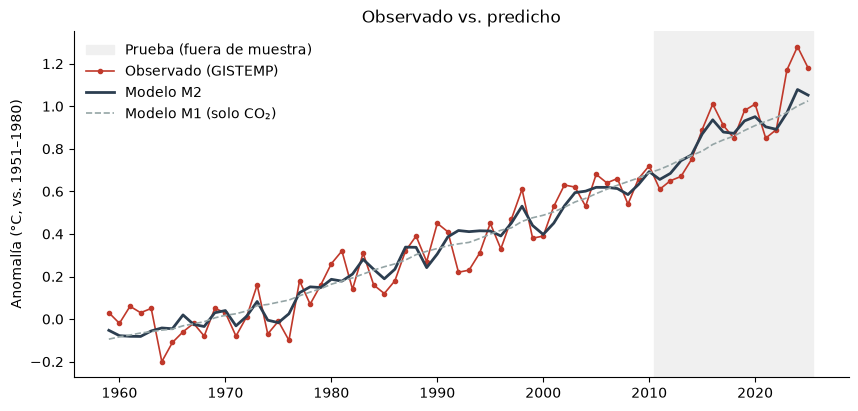

In [11]:
m = models["M2: CO₂ + ONI"]
pred = m.get_prediction(df).summary_frame(alpha=0.05)
df["pred"] = pred["mean"].values

fig, ax = plt.subplots()
ax.axvspan(TRAIN_END + 0.5, df.year.max() + 0.5, color="#f0f0f0", label="Prueba (fuera de muestra)")
ax.plot(df.year, df.temp_anom, "o-", color="#c0392b", ms=3, lw=1.2, label="Observado (GISTEMP)")
ax.plot(df.year, df.pred, color="#2c3e50", lw=2, label="Modelo M2")
ax.plot(df.year, models["M1: CO₂"].predict(df), color="#95a5a6", lw=1.2, ls="--", label="Modelo M1 (solo CO₂)")
ax.set_ylabel("Anomalía (°C, vs. 1951–1980)")
ax.set_title("Observado vs. predicho")
ax.legend(frameon=False, loc="upper left")
plt.show()

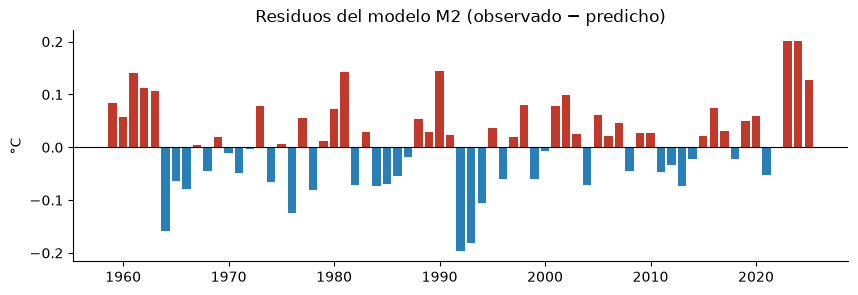

 año  residuo (°C)
1982        -0.071
1983         0.029
1991         0.024
1992        -0.196
1993        -0.181


In [12]:
resid = df.temp_anom - df.pred
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(df.year, resid, color=np.where(resid > 0, "#c0392b", "#2980b9"), width=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Residuos del modelo M2 (observado − predicho)")
ax.set_ylabel("°C")
plt.show()
# Los residuos negativos grandes en 1992–1993 suelen ser el enfriamiento del Pinatubo:
# el siguiente predictor a agregar es la profundidad óptica de aerosoles volcánicos.
volc = df.year.isin([1982, 1983, 1991, 1992, 1993])
print(pd.DataFrame({"año": df.year[volc], "residuo (°C)": resid[volc].round(3)}).to_string(index=False))

## 8. Interpretación de los coeficientes

In [13]:
b = m.params
F_per_ln = 5.35  # W/m² por unidad de ln(C/C0)
print(f"Sensibilidad empírica: {b['ln_co2']:.2f} °C por unidad de ln(CO₂/280)")
print(f"  ≈ {b['ln_co2'] * np.log(2):.2f} °C por duplicación de CO₂ (respuesta transitoria, solo CO₂ como proxy)")
print(f"  ≈ {b['ln_co2'] / F_per_ln:.2f} °C por W/m²")
print(f"Efecto ENSO: {b['oni']:.3f} °C por °C de ONI en el mismo año, {b['oni_lag1']:.3f} con un año de rezago")

Sensibilidad empírica: 3.78 °C por unidad de ln(CO₂/280)
  ≈ 2.62 °C por duplicación de CO₂ (respuesta transitoria, solo CO₂ como proxy)
  ≈ 0.71 °C por W/m²
Efecto ENSO: 0.039 °C por °C de ONI en el mismo año, 0.059 con un año de rezago
